# C4 comparing actions

Track C, Apetit Climate & Nature Navigator 2026.

This notebook prices actions that could reduce the climate cost from step 9. It is step 10 of the farm climate-risk recipe.

Each action is an action spec in `actions/catalogue.json`. A spec names the driver it targets, the step it changes, the override, its scope, its cost and a confidence level. An action never edits raw data. It changes one assumption about the future on a copy of the projection inputs, creating a what-if run. The what-if is then simulated and priced exactly like the no-action case:

- the same seasons;
- the same random draws for the model's leftover error;
- the same contracted volume, prices and import factors.

The difference between the two is what the action buys.

The notebook runs in this order:

1. Rebuild the no-action case and check it matches steps 8 and 9 exactly.
2. Break each crop's loss into its weather drivers. This is what the action proposer agent will read on the platform.
3. Check each action in the catalogue against the model, and refuse the ones it cannot price.
4. Run and price the rest.

The catalogue here is a team draft standing in for the action proposer agent. On the platform, only actions a person has approved would run. All money is in 2025 euros; costs and benefits are per year in 2041–60 unless marked "today".

It needs the outputs of steps 8 and 9. The code is in `actions.py`.

## 0. Setup

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from navigator.analysis import cropweather as cw
from navigator.analysis import yieldmodel as ym
from navigator.analysis import climateproj as cp
from navigator.analysis import riskprice as rp
from navigator.analysis import actions as ac

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
PKG = Path(os.environ.get("CCN_PKG", "../APETIT_CLIMATE_NATURE_NAVIGATOR_2026")).resolve()
OUT, RESULTS = Path("outputs"), Path("results")
for f in [OUT / "yield_projection_draws.parquet", RESULTS / "climate_risk_eur.csv", RESULTS / "import_ef.json"]:
    assert f.exists(), f"run steps 8 and 9 first ({f} missing)"

UNITS = [("FI_SW", "pea"), ("SE_SKANE", "pea"), ("FI_SW", "turnip_rape"),
         ("FI_SW", "potato"), ("FI_SW", "carrot"), ("FI_SW", "spinach")]
LABEL = {("FI_SW", "pea"): "Pea, Finland", ("SE_SKANE", "pea"): "Pea, Sweden", ("FI_SW", "turnip_rape"): "Turnip rape, Finland",
         ("FI_SW", "potato"): "Potato, Finland", ("FI_SW", "carrot"): "Carrot, Finland", ("FI_SW", "spinach"): "Spinach, Finland"}
SSP = ["baseline", "ssp126", "ssp245", "ssp585"]
NAME = {"baseline": "today", "ssp126": "ssp126", "ssp245": "ssp245", "ssp585": "ssp585"}
COLS = ["farm_id", "scenario", "year", "parcel_area_ha", "log_yield"]

## 1. Rebuild the no-action case

The same weather sets, parcels, management and model as step 8, through the same shared function. The check at the end of the section confirms that the no-action costs equal step 9's, to the cent.

In [2]:
keys, arr = cw.load_weather(PKG / "data/04_climate/weather_daily_1991_2060.parquet")
k, a = cp.ensemble(keys, arr, pd.read_csv(PKG / "data/04_climate/climate_change_signals.csv"))
del arr
stress, sat = cw.soil_water(a)

params = json.load(open(RESULTS / "crop_params.json"))["crop_params"]
MODELS = json.load(open(OUT / "yield_model.json"))
hist = pd.read_csv(OUT / "c1_model_table.csv")
pyf = pd.read_parquet(OUT / "c1_parcel_year_features.parquet")
p2025 = pyf[pyf["status"].eq("declared") & pyf["year"].eq(2025)][
    ["parcel_id", "farm_id", "region", "crop", "parcel_area_ha", "soil_class_soilmap", "clay_pct_soilmap", "slope_pct", "cell_id"]]
per_farm, unit_mgmt = ym.management_defaults(hist)

def crop_params(u):
    p = params[f"{u[0]}/{u[1]}"]
    return cw.CropParams(**{**p, "flower": tuple(p["flower"]), "sensitive": tuple(p["sensitive"])})

def rows_for(u, prm=None):
    return cp.parcel_seasons(k, a, stress, sat, prm or crop_params(u), p2025, per_farm, unit_mgmt, MODELS[f"{u[0]}/{u[1]}"], u)

ROWS = {u: rows_for(u) for u in UNITS}

draws_step8 = pd.read_parquet(OUT / "yield_projection_draws.parquet")
contracted = rp.contracted_volume(draws_step8)                      # fixed: the tonnes Apetit needs
normal = contracted.set_index(["region", "crop"])["normal_yield_t_ha"]
prem = rp.premiums(pd.read_csv(PKG / "data/05_scenarios/contract_prices_and_replacement_premiums.csv"),
                   pd.read_csv(PKG / "data/05_scenarios/transition_scenarios.csv"))
IMPORT_EF = {tuple(key.split("/")): v for key, v in json.load(open(RESULTS / "import_ef.json")).items()}

def priced(u, rows):
    d = cp.simulate(rows[COLS], MODELS[f"{u[0]}/{u[1]}"]).assign(region=u[0], crop=u[1])
    return rp.price_draws(d, contracted, prem, IMPORT_EF)

BASE = {u: priced(u, ROWS[u]) for u in UNITS}
step9 = pd.read_csv(RESULTS / "climate_risk_eur.csv")
mine = rp.summarise(pd.concat(BASE.values(), ignore_index=True))
m = mine.merge(step9, on=["region", "crop", "scenario", "ngfs"], suffixes=("", "_step9"))
print("no-action case matches step 9:", len(m) == len(step9) and np.allclose(m["expected_cost_eur"], m["expected_cost_eur_step9"], rtol=0, atol=0.01))

no-action case matches step 9: True


## 2. What drives each crop's loss

For each crop, the change in yield from 1991–2020 to 2041–60 is split by weather driver, using the model's own coefficients: the coefficient times the change in that driver's average. This is the input the action proposer works from. A negative number is a driver that lowers yields.

In [3]:
DRIVERS = {"drought_stage": "drought in the sensitive stage", "drought_early": "early drought", "heat_days_27": "heat at flowering",
           "harvest_rain_14_mm": "rain before harvest", "may_tmean_c": "warm May (pollen beetle)", "blight_days": "blight weather",
           "waterlog_clay": "waterlogging on clay", "immature_gap": "failure to mature",
           "drought_x_irr": "irrigation offset", "blight_x_sprays": "spraying offset"}
rows = []
for u, x in ROWS.items():
    beta = MODELS[f"{u[0]}/{u[1]}"]["beta"]
    w = x["parcel_area_ha"]
    mean = (x[list(DRIVERS)].mul(w, axis=0)).groupby(x["scenario"]).sum().div(w.groupby(x["scenario"]).sum(), axis=0)
    for s in ["ssp126", "ssp245", "ssp585"]:
        for f, name in DRIVERS.items():
            eff = 100 * (np.exp(beta.get(f, 0.0) * (mean.loc[s, f] - mean.loc["baseline", f])) - 1)
            rows.append({"unit": LABEL[u], "region": u[0], "crop": u[1], "scenario": s, "driver": name, "yield_effect_pct": eff})
drivers = pd.DataFrame(rows)
dt = drivers[drivers["scenario"].eq("ssp585")].pivot(index="driver", columns="unit", values="yield_effect_pct")[[LABEL[u] for u in UNITS]]
dt = dt.loc[dt.abs().max(axis=1) > 0.2]
dt.round(1)

unit,"Pea, Finland","Pea, Sweden","Turnip rape, Finland","Potato, Finland","Carrot, Finland","Spinach, Finland"
driver,,,,,,
blight weather,0.0,0.0,0.0,0.2,0.0,0.0
drought in the sensitive stage,-0.6,-0.5,-0.4,-2.0,-0.7,1.0
early drought,1.5,0.9,1.3,0.0,-0.5,1.2
failure to mature,0.0,0.0,0.0,1.0,0.0,0.0
heat at flowering,-3.7,0.0,-2.1,-2.2,0.1,-0.4
irrigation offset,0.0,0.1,0.0,1.0,0.3,-0.0
rain before harvest,-0.6,-0.2,-0.0,-0.1,0.1,0.1
spraying offset,0.0,0.0,0.0,-0.2,0.0,0.0
warm May (pollen beetle),0.0,0.0,-3.6,0.0,0.0,0.0


In [4]:
top = (drivers[drivers["yield_effect_pct"] < 0].sort_values("yield_effect_pct").groupby(["unit", "scenario"]).head(1)
       .pivot(index="unit", columns="scenario", values="driver").loc[[LABEL[u] for u in UNITS]])
top.columns = [f"largest loss driver, {c}" for c in top.columns]
top

,"largest loss driver, ssp126","largest loss driver, ssp245","largest loss driver, ssp585"
unit,,,
"Pea, Finland",heat at flowering,heat at flowering,heat at flowering
"Pea, Sweden",drought in the sensitive stage,drought in the sensitive stage,drought in the sensitive stage
"Turnip rape, Finland",warm May (pollen beetle),warm May (pollen beetle),warm May (pollen beetle)
"Potato, Finland",blight weather,heat at flowering,heat at flowering
"Carrot, Finland",early drought,early drought,drought in the sensitive stage
"Spinach, Finland",heat at flowering,heat at flowering,heat at flowering


Under the hottest scenario, heat at flowering drives Finnish pea's loss and warm Mays drive turnip rape's. Swedish pea and carrot lose mostly to drought in the sensitive stage, and potato to heat at flowering and drought about equally. The effects are a few percent each, consistent with step 8. These drivers match the actions in the catalogue: heat-tolerant varieties and earlier sowing for heat, irrigation for drought, and relocation for the farms that lose most.

## 3. The action catalogue

Each spec is checked against the model before it runs. An action whose effect the model cannot estimate is refused with a reason, not priced on a guess.

In [5]:
CATALOGUE = ac.load_catalogue("../config/actions/catalogue.json")
rows = []
for spec in CATALOGUE:
    ok, why = ac.support(spec, MODELS)
    rows.append({"action": spec["action_id"], "name": spec["short_name"], "targets": spec["driver"],
                 "cost per year (EUR)": spec["cost"]["eur_per_year"], "confidence": spec["confidence"].split(":")[0],
                 "runs": "yes" if ok else "no", "why not": why})
catalogue_table = pd.DataFrame(rows).set_index("action")
catalogue_table

,name,targets,cost per year (EUR),confidence,runs,why not
action,,,,,,
A1-relocate-fi-pea,Relocate 20% of Finnish pea area,"heat at flowering, Finnish pea",NaN,medium,yes,
A2-relocate-fi-turnip-rape,Relocate 20% of turnip rape area,"warm May (pollen beetle), turnip rape",NaN,medium,yes,
A3-irrigate-potato-carrot,Irrigate all potato and carrot (L24),"drought in the sensitive stage, potato and carrot",60000.0,medium,yes,
A4-irrigate-fi-pea,Irrigate Finnish pea,"drought in the sensitive stage, Finnish pea",NaN,low,no,no irrigation effect in the FI_SW/pea model: these growers never irrigate in...
A5-early-sowing-fi-pea,Sow Finnish pea up to 14 days earlier,"heat at flowering, Finnish pea",0.0,low,yes,
A6-heat-tolerant-pea-fi,Heat-tolerant Finnish pea (assumed),"heat at flowering, Finnish pea",NaN,low,yes,


## 4. Run and price each action

Each runnable action becomes a what-if run for the crops in its scope, priced against the same contracted volume as the no-action case. For each climate, the result is the cost the action removes: per year on average, and in a 1-in-10 bad year. For ssp126 and ssp245 the values are averaged over their three paired NGFS scenarios. "Climate-driven" is the part of the benefit that comes on top of what the action already buys today.

In [6]:
def per_climate(priced_rows):
    t = priced_rows.groupby(["scenario", "ngfs", "season", "rep"], sort=False)[["extra_cost_eur", "import_tco2e"]].sum().reset_index()
    g = t.groupby(["scenario", "ngfs"], sort=False).agg(expected=("extra_cost_eur", "mean"),
                                                         one_in_ten=("extra_cost_eur", lambda s: s.quantile(0.9)),
                                                         tco2e=("import_tco2e", "mean"))
    return g.groupby(level="scenario", sort=False).mean()

OPTIONS, DETAILS, WHATIF = [], {}, []
for spec in CATALOGUE:
    if not ac.support(spec, MODELS)[0]:
        continue
    base, act = [], []
    for u in ac.units(spec):
        rebuild = lambda days, u=u: rows_for(u, ac.shifted_params(crop_params(u), days))
        x, det = ac.apply_override(spec, ROWS[u], MODELS[f"{u[0]}/{u[1]}"], normal[u], rebuild)
        DETAILS[(spec["action_id"], u)] = det
        p = priced(u, x)
        base.append(BASE[u]); act.append(p)
        WHATIF.append(p.assign(action_id=spec["action_id"]))
    b, w = per_climate(pd.concat(base)), per_climate(pd.concat(act))
    cost = spec["cost"]["eur_per_year"]
    for s in SSP:
        removed = b.loc[s, "expected"] - w.loc[s, "expected"]
        OPTIONS.append({"action_id": spec["action_id"], "name": spec["name"], "scenario": s,
                        "expected_cost_no_action_eur": b.loc[s, "expected"], "expected_cost_with_action_eur": w.loc[s, "expected"],
                        "risk_removed_eur": removed, "one_in_ten_removed_eur": b.loc[s, "one_in_ten"] - w.loc[s, "one_in_ten"],
                        "import_tco2e_removed": b.loc[s, "tco2e"] - w.loc[s, "tco2e"],
                        "action_cost_eur": cost, "net_benefit_eur": None if cost is None else removed - cost,
                        "break_even_cost_eur": removed, "confidence": spec["confidence"]})
options = pd.DataFrame(OPTIONS)
today = options[options["scenario"].eq("baseline")].set_index("action_id")["risk_removed_eur"]
options["climate_driven_removed_eur"] = options["risk_removed_eur"] - options["action_id"].map(today)

view = options.assign(climate=options["scenario"].map(NAME))
show = view.pivot(index="action_id", columns="climate", values="risk_removed_eur")[["today", "ssp126", "ssp245", "ssp585"]].div(1000).add_prefix("removed kEUR/yr ")
show["of which climate-driven, ssp585"] = view[view["scenario"].eq("ssp585")].set_index("action_id")["climate_driven_removed_eur"] / 1000
show["1-in-10 removed kEUR, ssp585"] = view[view["scenario"].eq("ssp585")].set_index("action_id")["one_in_ten_removed_eur"] / 1000
show["t CO2e/yr avoided, ssp585"] = view[view["scenario"].eq("ssp585")].set_index("action_id")["import_tco2e_removed"]
show["cost kEUR/yr"] = view.drop_duplicates("action_id").set_index("action_id")["action_cost_eur"] / 1000
show.round(1)

climate,removed kEUR/yr today,removed kEUR/yr ssp126,removed kEUR/yr ssp245,removed kEUR/yr ssp585,"of which climate-driven, ssp585","1-in-10 removed kEUR, ssp585","t CO2e/yr avoided, ssp585",cost kEUR/yr
action_id,,,,,,,,
A1-relocate-fi-pea,35.9,39.2,40.0,48.5,12.6,96.1,93.7,NaN
A2-relocate-fi-turnip-rape,7.2,6.7,7.1,9.2,2.0,17.0,330.9,NaN
A3-irrigate-potato-carrot,58.2,63.6,68.6,76.1,17.9,170.2,201.8,60.0
A5-early-sowing-fi-pea,8.0,23.0,25.5,29.1,21.1,109.0,56.1,0.0
A6-heat-tolerant-pea-fi,20.2,30.5,32.5,39.2,18.9,129.0,75.6,NaN


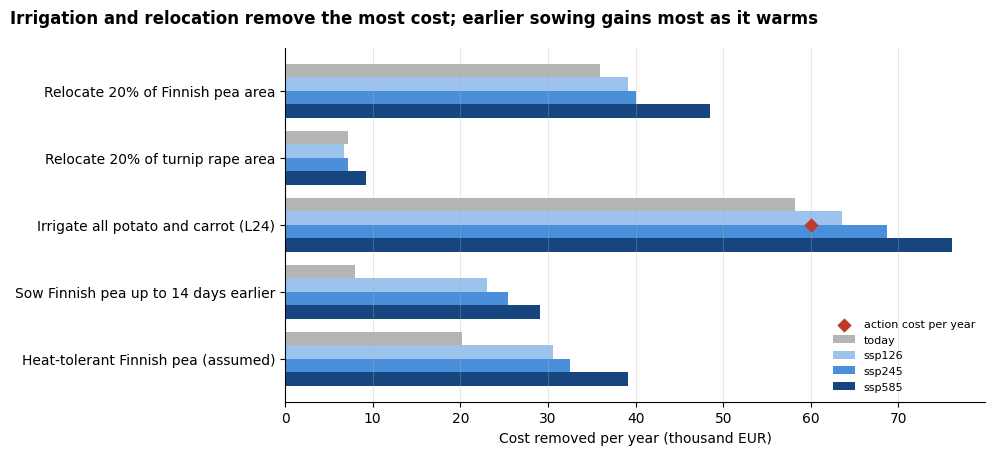

In [7]:
acts = list(show.index)[::-1]
y = np.arange(len(acts)); h = 0.2
colors = {"today": "#b5b5b5", "ssp126": "#9cc3ec", "ssp245": "#4a8fd9", "ssp585": "#16457f"}
fig, ax = plt.subplots(figsize=(10, 4.6))
for i, c in enumerate(["today", "ssp126", "ssp245", "ssp585"]):
    ax.barh(y + (1.5 - i) * h, show.loc[acts, f"removed kEUR/yr {c}"], h, color=colors[c], label=c)
cost = show.loc[acts, "cost kEUR/yr"]
known = cost.notna() & (cost > 0)
ax.scatter(cost[known], y[known.values], marker="D", s=40, color="#c0392b", zorder=3, label="action cost per year")
names = {s["action_id"]: s["short_name"] for s in CATALOGUE}
ax.set_yticks(y); ax.set_yticklabels([names[i] for i in acts])
ax.set_xlabel("Cost removed per year (thousand EUR)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", alpha=0.3)
ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Irrigation and relocation remove the most cost; earlier sowing gains most as it warms", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.tight_layout()
fig.savefig(RESULTS / "action_options.png", dpi=150, bbox_inches="tight")
plt.show()

How to read the results:

- Irrigation for the potato and carrot growers who don't yet irrigate removes about as much cost as lever L24 costs today, and more as the climate warms. It is the only action with a cost from the package, and that cost is a design estimate.
- Moving 20% of Finnish pea area to the farms that lose least removes the most cost for pea, but most of that benefit exists today: it mainly moves area to better-performing farms. Only a modest part is climate-driven. It has no cost in the package, so the table gives its break-even cost: the most Apetit could spend on recruitment and advice per year and still gain.
- Earlier sowing for Finnish pea is a true adaptation. It is worth little today and grows with warming, because it moves flowering away from the hottest weeks. Its confidence is low: no recorded season was sown that early, and frost after sowing isn't modelled.
- Heat-tolerant pea varieties follow the same pattern, but their 30% effect is an assumption, so the result shows what such a variety would be worth, not that one exists.
- Relocating turnip rape removes little in euros, because its replacement premium is only 8%. But it avoids the most import emissions of any action, about 330 t CO2e a year under ssp585, because imported rapeseed has a high footprint.

## 5. Details and refusals

Relocation moves whole farms, so the share moved lands slightly above the 20% asked for. The table shows what moved under each climate. The refused actions follow, with their reason.

In [8]:
det = pd.DataFrame([{"action": a_id, "unit": LABEL[u], "climate": NAME.get(s, s), **v}
                    for (a_id, u), d in DETAILS.items() if d for s, v in d.items() if s in SSP])
det.round(3)

,action,unit,climate,moved_ha,share,farms_dropped,farms_receiving
0,A1-relocate-fi-pea,"Pea, Finland",today,416.97,0.207,26,24
1,A1-relocate-fi-pea,"Pea, Finland",ssp126,425.06,0.211,27,25
2,A1-relocate-fi-pea,"Pea, Finland",ssp245,403.26,0.200,25,23
3,A1-relocate-fi-pea,"Pea, Finland",ssp585,417.76,0.207,25,25
4,A2-relocate-fi-turnip-rape,"Turnip rape, Finland",today,1035.89,0.206,50,49
5,A2-relocate-fi-turnip-rape,"Turnip rape, Finland",ssp126,1010.92,0.201,49,44
6,A2-relocate-fi-turnip-rape,"Turnip rape, Finland",ssp245,1010.92,0.201,49,46
7,A2-relocate-fi-turnip-rape,"Turnip rape, Finland",ssp585,1032.92,0.206,50,48


In [9]:
refused = catalogue_table[catalogue_table["runs"].eq("no")][["name", "why not"]]
refused

,name,why not
action,,
A4-irrigate-fi-pea,Irrigate Finnish pea,no irrigation effect in the FI_SW/pea model: these growers never irrigate in...


Irrigation for Finnish pea is refused because no Finnish pea grower irrigates in the data, so the model has never seen what irrigation does for that crop. The platform should treat this as a question for experts, not a zero.

## 6. Checks
If any check fails, the notebook stops before writing anything.

In [10]:
def area_kept(a_id, u):
    w = [p for p in WHATIF if p["action_id"].iat[0] == a_id and p["crop"].iat[0] == u[1] and p["region"].iat[0] == u[0]][0]
    return np.allclose(w.groupby(["scenario", "season", "rep"])["area_ha"].first().values,
                       BASE[u].groupby(["scenario", "season", "rep"])["area_ha"].first().reindex(
                           w.groupby(["scenario", "season", "rep"])["area_ha"].first().index).values)

checks = {
    "no-action case matches step 9": len(m) == len(step9) and np.allclose(m["expected_cost_eur"], m["expected_cost_eur_step9"], rtol=0, atol=0.01),
    "every runnable action priced for all four climates": options.groupby("action_id")["scenario"].nunique().eq(4).all(),
    "refused actions were not priced": not set(refused.index) & set(options["action_id"]),
    "relocation keeps total area": all(area_kept(a_id, u) for (a_id, u), d in DETAILS.items() if d),
    "contracted volume unchanged by any action": all(
        np.allclose(p.groupby(["region", "crop"])["contracted_t"].first().values,
                    contracted.set_index(["region", "crop"]).loc[p.groupby(["region", "crop"])["contracted_t"].first().index, "contracted_t"].values)
        for p in WHATIF),
}
for name, ok in checks.items():
    print(("PASS " if ok else "FAIL ") + name)
assert all(checks.values())

PASS no-action case matches step 9
PASS every runnable action priced for all four climates
PASS refused actions were not priced
PASS relocation keeps total area
PASS contracted volume unchanged by any action


## 7. Write the outputs

In [11]:
options.round(3).to_csv(RESULTS / "action_options.csv", index=False)
drivers.round(3).to_csv(RESULTS / "loss_drivers.csv", index=False)
refused.to_csv(RESULTS / "actions_not_run.csv")
pd.concat(WHATIF, ignore_index=True).to_parquet(OUT / "action_whatif_priced.parquet", index=False)
for f in ["action_options.csv", "loss_drivers.csv", "actions_not_run.csv", "action_options.png"]:
    print(f"results/{f:24s} {(RESULTS / f).stat().st_size / 1e6:6.3f} MB  (versioned)")

results/action_options.csv        0.005 MB  (versioned)
results/loss_drivers.csv          0.011 MB  (versioned)
results/actions_not_run.csv       0.000 MB  (versioned)
results/action_options.png        0.075 MB  (versioned)


## Points for the method note

- Each action is a what-if run: the no-action projection with one assumption changed, simulated with the same random draws and priced against the same contracted volume, so the difference is the action's effect alone.
- Actions the model can't estimate are refused with a reason rather than priced on a guess. Irrigation for Finnish pea is the example: its growers never irrigate in the data.
- Costs come from the package where it has them (lever L24, a design estimate). Otherwise the result is the break-even cost, the most Apetit could spend per year and still come out ahead.
- Relocation ranks farms by their own projected losses under the same climate, so its benefit is somewhat optimistic: in practice, the farms that will do best can't be known exactly in advance.
- The catalogue is a team draft standing in for the action proposer agent. On the platform, actions run only after a person approves them, and results go to results review.